<a href="https://colab.research.google.com/github/mafaiziyas/sp500-market-segmentation-fintech-analytics/blob/main/notebooks/Task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [20]:
# helper func to print section headings
def heading(text):
    print("\n" + "=" * 60)
    print(text)
    print("=" * 60)

#Task 2.1

In [21]:
#Read
ft = pd.read_csv(f"/content/drive/MyDrive/sp500 CW/data_snapshots/feature_table.csv", index_col="Ticker")

folder = "/content/drive/MyDrive/sp500 CW/data_snapshots"

# Two separate matrices, same 488 shares and same order
X_risk = ft[["mean_weekly_return", "weekly_beta"]].copy()
X_act = ft[["recency_days", "frequency", "monetary_usd"]].copy()
X_act["log1p_monetary"] = np.log1p(X_act.pop("monetary_usd"))

print("Same shares, same order:", list(X_risk.index) == list(X_act.index), "| n =", len(X_risk))

#Skew before and after the log transform on M
print("\nSkew of Monetary before:", round(ft["monetary_usd"].skew(), 2),
      "| after log1p:", round(X_act["log1p_monetary"].skew(), 2))

#Skew of every input feature (decision evidence for the other variables)
print("\nSkew of inputs:")
print(pd.concat([X_risk, X_act], axis=1).skew().round(2))

# Optional diagnostic for R only (do not use unless you decide to)
print("\nR skew if log1p were applied:", round(np.log1p(X_act["recency_days"]).skew(), 2))

# Standardise each matrix separately
scaler_risk, scaler_act = StandardScaler(), StandardScaler()
Z_risk = pd.DataFrame(scaler_risk.fit_transform(X_risk), index=X_risk.index, columns=X_risk.columns)
Z_act = pd.DataFrame(scaler_act.fit_transform(X_act), index=X_act.index, columns=X_act.columns)

# Check: mean 0, standard deviation 1
for name, Z in [("Risk/return", Z_risk), ("Trading activity", Z_act)]:
    print(f"\n{name}: means", Z.mean().round(6).tolist(), "| stds", Z.std(ddof=0).round(6).tolist())

# Outliers: how many shares lie beyond 3 standard deviations, and which
for name, Z in [("Risk/return", Z_risk), ("Trading activity", Z_act)]:
    print(f"\n{name} outliers (|z| > 3):")
    print((Z.abs() > 3).sum())
    print("Most extreme shares:", Z.abs().max(axis=1).sort_values(ascending=False).head(5).round(1).to_dict())

# Save prepared matrices
Z_risk.to_csv(f"{folder}/risk_processed.csv")
Z_act.to_csv(f"{folder}/activity_processed.csv")

Same shares, same order: True | n = 488

Skew of Monetary before: 11.71 | after log1p: 1.08

Skew of inputs:
mean_weekly_return    0.87
weekly_beta           1.10
recency_days          3.65
frequency             0.43
log1p_monetary        1.08
dtype: float64

R skew if log1p were applied: 1.58

Risk/return: means [0.0, -0.0] | stds [1.0, 1.0]

Trading activity: means [-0.0, -0.0, -0.0] | stds [1.0, 1.0, 1.0]

Risk/return outliers (|z| > 3):
mean_weekly_return    6
weekly_beta           2
dtype: int64
Most extreme shares: {'CVNA': 6.9, 'SMCI': 5.6, 'NVDA': 4.1, 'XYZ': 3.8, 'VRT': 3.7}

Trading activity outliers (|z| > 3):
recency_days      11
frequency          5
log1p_monetary     7
dtype: int64
Most extreme shares: {'NVDA': 9.5, 'WEC': 6.1, 'TSLA': 4.9, 'HRL': 3.8, 'DUK': 3.8}


In [22]:
from sklearn.preprocessing import StandardScaler

# Raw activity matrix (before log1p) vs transformed activity matrix (after log1p)
X_raw = ft[["recency_days", "frequency", "monetary_usd"]].copy()
Z_before = StandardScaler().fit_transform(X_raw)
Z_after = Z_act.values

for label, Z_mat in [("Before log1p", Z_before), ("After log1p", Z_after)]:
    sq_dist_from_center = np.sum(Z_mat ** 2, axis=1)  # squared Euclidean distance from centroid (0,0,0)
    top5_share = np.sort(sq_dist_from_center)[-5:].sum() / sq_dist_from_center.sum() * 100
    print(f"{label}: Top-5 shares account for {top5_share:.1f}% of total squared Euclidean distance")

Before log1p: Top-5 shares account for 39.1% of total squared Euclidean distance
After log1p: Top-5 shares account for 15.8% of total squared Euclidean distance


#Task 2.2

In [23]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

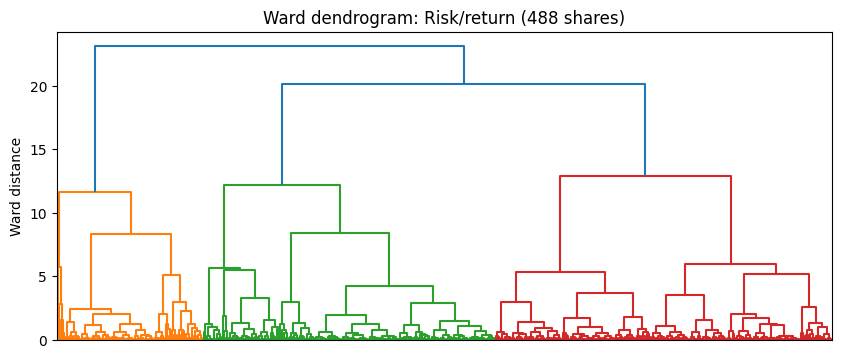

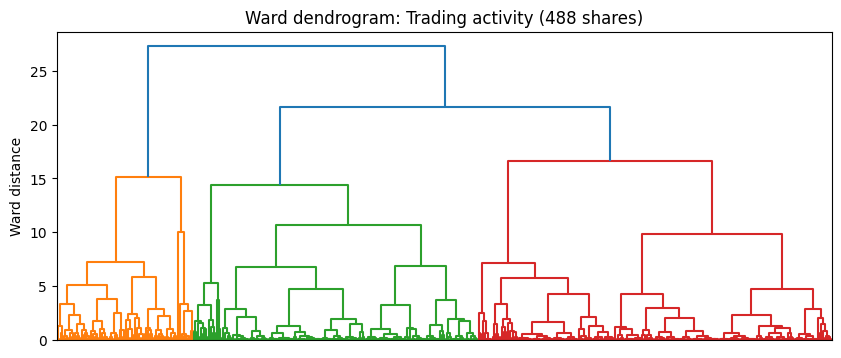

Risk/return
 k  silhouette  smallest                             sizes
 2       0.340        92                         [396, 92]
 3       0.293        92                    [212, 184, 92]
 4       0.265        92                [184, 114, 98, 92]
 5       0.287        48            [136, 114, 98, 92, 48]
 6       0.304         5         [136, 114, 98, 87, 48, 5]
 7       0.306         5     [114, 114, 98, 87, 48, 22, 5]
 8       0.314         5 [114, 114, 98, 56, 48, 31, 22, 5]

Trading activity
 k  silhouette  smallest                           sizes
 2       0.369        86                       [402, 86]
 3       0.261        86                  [223, 179, 86]
 4       0.251        86              [179, 137, 86, 86]
 5       0.270        10          [179, 137, 86, 76, 10]
 6       0.291        10      [161, 137, 86, 76, 18, 10]
 7       0.280        10   [137, 90, 86, 76, 71, 18, 10]
 8       0.282         1 [137, 90, 86, 76, 71, 18, 9, 1]



In [24]:
matrices = {"Risk/return": Z_risk, "Trading activity": Z_act}
links = {name: linkage(Z, method="ward", metric="euclidean") for name, Z in matrices.items()}

#One dendrogram per matrix
for name, L in links.items():
    plt.figure(figsize=(10, 4))
    dendrogram(L, no_labels=True)
    plt.title(f"Ward dendrogram: {name} (488 shares)")
    plt.ylabel("Ward distance")
    plt.savefig(f"{folder}/dendrogram_{name.split('/')[0].split()[0].lower()}.png", dpi=200, bbox_inches="tight")
    plt.show()

# Compareing k = 2 to 8: silhouette and cluster size
rows = []
for name, Z in matrices.items():
    for k in range(2, 9):
        labels = fcluster(links[name], k, criterion="maxclust")
        sizes = np.bincount(labels)[1:]
        rows.append({"matrix": name, "k": k,
                     "silhouette": round(silhouette_score(Z, labels), 3),
                     "smallest": int(sizes.min()),
                     "sizes": sorted(sizes.tolist(), reverse=True)})
ward_results = pd.DataFrame(rows)
for name in matrices:
    print(name)
    print(ward_results[ward_results["matrix"] == name].drop(columns="matrix").to_string(index=False))
    print()


In [25]:
orig = {
    "Risk/return": ft[["mean_weekly_return", "weekly_beta"]],
    "Trading activity": ft[["recency_days", "frequency", "monetary_usd"]]
        .assign(monetary_usd=lambda d: d["monetary_usd"] / 1e9)
        .rename(columns={"monetary_usd": "monetary_usd_bn"}),
}

for name in matrices:
    for k in [2, 3, 4, 5]:
        labels = fcluster(links[name], k, criterion="maxclust")
        prof = orig[name].groupby(labels).median().round(3)
        prof.insert(0, "n", np.bincount(labels)[1:])
        print(f"\n{name} | k = {k}")
        print(prof)

ward_results.to_csv(f"{folder}/ward_k_comparison.csv", index=False)


Risk/return | k = 2
     n  mean_weekly_return  weekly_beta
1   92               0.006        1.218
2  396               0.002        0.885

Risk/return | k = 3
     n  mean_weekly_return  weekly_beta
1   92               0.006        1.218
2  184               0.002        1.089
3  212               0.003        0.632

Risk/return | k = 4
     n  mean_weekly_return  weekly_beta
1   92               0.006        1.218
2  184               0.002        1.089
3   98               0.004        0.666
4  114               0.001        0.570

Risk/return | k = 5
     n  mean_weekly_return  weekly_beta
1   92               0.006        1.218
2   48               0.003        1.514
3  136               0.002        1.038
4   98               0.004        0.666
5  114               0.001        0.570

Trading activity | k = 2
     n  recency_days  frequency  monetary_usd_bn
1   86          54.0        2.0           21.450
2  402          11.0        3.0           15.396

Trading activity | k =

#Task 2.3

Risk/return
 k  inertia  silhouette  smallest                            sizes
 2    625.0       0.387       143                       [345, 143]
 3    464.1       0.328       119                  [203, 166, 119]
 4    373.9       0.325        41              [161, 154, 132, 41]
 5    311.8       0.340        37          [163, 128, 111, 49, 37]
 6    266.6       0.335         5       [158, 127, 105, 50, 43, 5]
 7    228.4       0.329         5    [131, 103, 85, 77, 46, 41, 5]
 8    195.4       0.355         5 [139, 80, 76, 76, 43, 40, 29, 5]

Trading activity
 k  inertia  silhouette  smallest                             sizes
 2   1071.6       0.424        68                         [420, 68]
 3    800.7       0.325        63                    [274, 151, 63]
 4    612.5       0.341        61                [214, 122, 91, 61]
 5    517.1       0.358        11            [200, 122, 87, 68, 11]
 6    439.8       0.346        11       [144, 119, 106, 67, 41, 11]
 7    389.1       0.341   

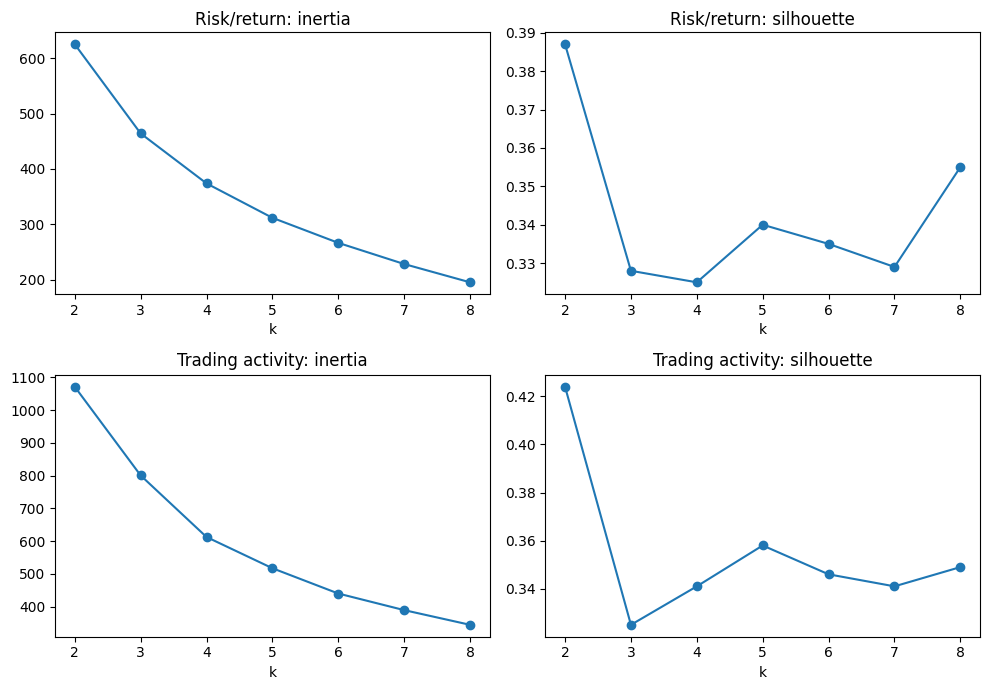

In [26]:
from sklearn.cluster import KMeans

SEED = 42

#Compare k = 2 to 8: inertia, silhouette, sizes (50 starts per k)
rows = []
for name, Z in matrices.items():
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
        sizes = np.bincount(km.labels_)
        rows.append({"matrix": name, "k": k,
                     "inertia": round(km.inertia_, 1),
                     "silhouette": round(silhouette_score(Z, km.labels_), 3),
                     "smallest": int(sizes.min()),
                     "sizes": sorted(sizes.tolist(), reverse=True)})
km_results = pd.DataFrame(rows)
for name in matrices:
    print(name)
    print(km_results[km_results["matrix"] == name].drop(columns="matrix").to_string(index=False))
    print()
km_results.to_csv(f"{folder}/kmeans_k_comparison.csv", index=False)

#Elbow (inertia) and silhouette plots
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, name in enumerate(matrices):
    d = km_results[km_results["matrix"] == name]
    axes[i, 0].plot(d["k"], d["inertia"], marker="o")
    axes[i, 0].set_title(f"{name}: inertia"); axes[i, 0].set_xlabel("k")
    axes[i, 1].plot(d["k"], d["silhouette"], marker="o")
    axes[i, 1].set_title(f"{name}: silhouette"); axes[i, 1].set_xlabel("k")
plt.tight_layout()
plt.savefig(f"{folder}/kmeans_k_diagnostics.png", dpi=200, bbox_inches="tight")
plt.show()

In [27]:
#Initialisation check at k = 5: one start versus 50 starts, and seed stability
K_CHECK = 5
for name, Z in matrices.items():
    single = [KMeans(n_clusters=K_CHECK, n_init=1, random_state=s).fit(Z).inertia_ for s in range(20)]
    best = KMeans(n_clusters=K_CHECK, n_init=50, random_state=SEED).fit(Z)
    aris = [adjusted_rand_score(best.labels_,
            KMeans(n_clusters=K_CHECK, n_init=50, random_state=s).fit_predict(Z)) for s in [1, 2, 3, 4, 5]]
    print(f"{name} | single-start inertia over 20 seeds: min {min(single):.1f}, max {max(single):.1f}"
          f" | 50 starts: {best.inertia_:.1f} | ARI vs other seeds (min): {min(aris):.3f}")

Risk/return | single-start inertia over 20 seeds: min 312.0, max 334.4 | 50 starts: 311.8 | ARI vs other seeds (min): 0.891
Trading activity | single-start inertia over 20 seeds: min 517.1, max 563.1 | 50 starts: 517.1 | ARI vs other seeds (min): 1.000


In [28]:
# Profiles in original units for the shortlist (medians), same style as Ward
for name, Z in matrices.items():
    for k in [3, 4, 5]:
        labels = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(Z)
        prof = orig[name].groupby(labels).median().round(3)
        prof.insert(0, "n", np.bincount(labels))
        print(f"\n{name} | K-means k = {k}")
        print(prof)


Risk/return | K-means k = 3
     n  mean_weekly_return  weekly_beta
0  203               0.003        0.622
1  166               0.001        1.081
2  119               0.005        1.221

Risk/return | K-means k = 4
     n  mean_weekly_return  weekly_beta
0   41               0.007        1.677
1  132               0.001        1.142
2  154               0.002        0.577
3  161               0.004        0.985

Risk/return | K-means k = 5
     n  mean_weekly_return  weekly_beta
0   49               0.003        1.533
1  128               0.002        0.524
2  163               0.004        0.990
3  111               0.001        1.033
4   37               0.008        1.384

Trading activity | K-means k = 3
     n  recency_days  frequency  monetary_usd_bn
0  274          11.0        3.0           11.443
1   63          55.0        2.0           21.242
2  151          11.0        3.0           42.013

Trading activity | K-means k = 4
     n  recency_days  frequency  monetary_usd_bn


In [31]:
# Comparison Tables
ward_results = pd.read_csv(f"{folder}/ward_k_comparison.csv")
km_results   = pd.read_csv(f"{folder}/kmeans_k_comparison.csv")

def k_table(matrix):
    w = ward_results[ward_results["matrix"] == matrix].set_index("k")
    m = km_results[km_results["matrix"] == matrix].set_index("k")
    t = pd.DataFrame(index=w.index)
    t["Ward silhouette (smallest cluster)"]    = [f"{s:.3f} ({n})" for s, n in zip(w["silhouette"], w["smallest"])]
    t["K-means silhouette (smallest cluster)"] = [f"{s:.3f} ({n})" for s, n in zip(m["silhouette"], m["smallest"])]
    t["K-means inertia"] = m["inertia"].round(1)
    return t

for name in ["Risk/return", "Trading activity"]:
    t = k_table(name)
    print(f"\nTable. {name}: silhouette by k (smallest cluster size in brackets) and K-means inertia")
    display(t)
    t.to_csv(f"{folder}/table_k_comparison_{name.split('/')[0].split()[0].lower()}.csv")


Table. Risk/return: silhouette by k (smallest cluster size in brackets) and K-means inertia


,Ward silhouette (smallest cluster),K-means silhouette (smallest cluster),K-means inertia
k,,,
2,0.340 (92),0.387 (143),625.0
3,0.293 (92),0.328 (119),464.1
4,0.265 (92),0.325 (41),373.9
5,0.287 (48),0.340 (37),311.8
6,0.304 (5),0.335 (5),266.6
7,0.306 (5),0.329 (5),228.4
8,0.314 (5),0.355 (5),195.4



Table. Trading activity: silhouette by k (smallest cluster size in brackets) and K-means inertia


,Ward silhouette (smallest cluster),K-means silhouette (smallest cluster),K-means inertia
k,,,
2,0.369 (86),0.424 (68),1071.6
3,0.261 (86),0.325 (63),800.7
4,0.251 (86),0.341 (61),612.5
5,0.270 (10),0.358 (11),517.1
6,0.291 (10),0.346 (11),439.8
7,0.280 (10),0.341 (1),389.1
8,0.282 (1),0.349 (1),344.2


#Task 2.4


In [29]:
from sklearn.decomposition import PCA

K_RISK, K_ACT = 4, 5

# Four final solutions (same shares, same order)
final = pd.DataFrame(index=ft.index)
final["ward_risk"]       = fcluster(links["Risk/return"], K_RISK, criterion="maxclust")
final["ward_activity"]   = fcluster(links["Trading activity"], K_ACT, criterion="maxclust")
final["kmeans_risk"]     = KMeans(n_clusters=K_RISK, n_init=50, random_state=SEED).fit_predict(Z_risk) + 1
final["kmeans_activity"] = KMeans(n_clusters=K_ACT, n_init=50, random_state=SEED).fit_predict(Z_act) + 1
final.to_csv(f"{folder}/cluster_labels_final.csv")

# Silhouette and sizes of the four final solutions
for col, Z in [("ward_risk", Z_risk), ("kmeans_risk", Z_risk), ("ward_activity", Z_act), ("kmeans_activity", Z_act)]:
    print(col, "| silhouette", round(silhouette_score(Z, final[col]), 3), "| sizes", final[col].value_counts().sort_index().tolist())

# Profiles in original units (median and mean), one table per solution
for col, key in [("ward_risk", "Risk/return"), ("kmeans_risk", "Risk/return"),
                 ("ward_activity", "Trading activity"), ("kmeans_activity", "Trading activity")]:
    g = orig[key].groupby(final[col])
    prof = g.median().round(3).add_suffix("_median").join(g.mean().round(3).add_suffix("_mean"))
    prof.insert(0, "n", g.size())
    print(f"\n{col}"); print(prof)

ward_risk | silhouette 0.265 | sizes [92, 184, 98, 114]
kmeans_risk | silhouette 0.325 | sizes [41, 132, 154, 161]
ward_activity | silhouette 0.27 | sizes [76, 10, 179, 86, 137]
kmeans_activity | silhouette 0.358 | sizes [122, 68, 11, 87, 200]

ward_risk
             n  mean_weekly_return_median  weekly_beta_median  \
ward_risk                                                       
1           92                      0.006               1.218   
2          184                      0.002               1.089   
3           98                      0.004               0.666   
4          114                      0.001               0.570   

           mean_weekly_return_mean  weekly_beta_mean  
ward_risk                                             
1                            0.006             1.298  
2                            0.002             1.200  
3                            0.004             0.710  
4                            0.001             0.574  

kmeans_risk
           

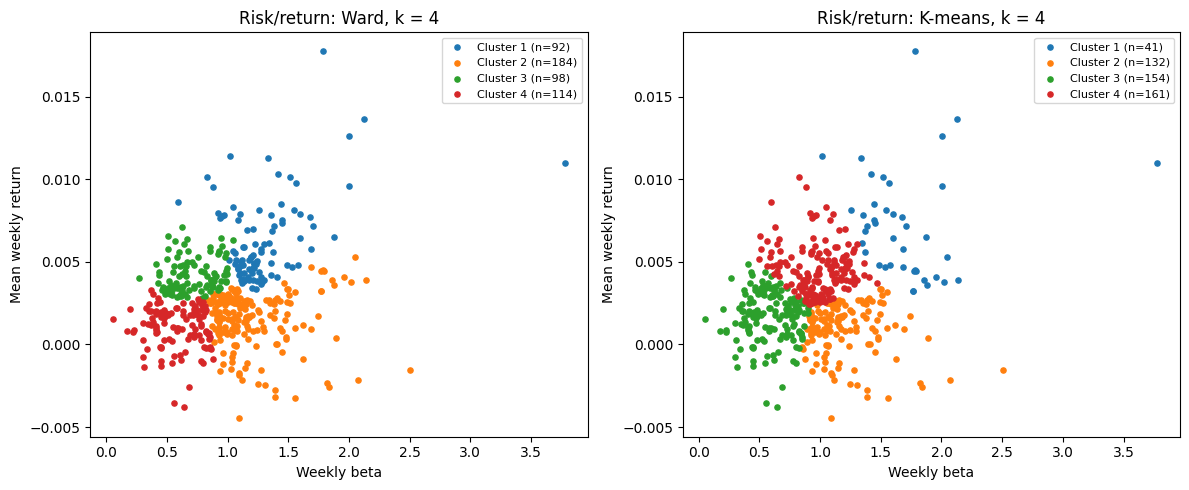

PCA explained variance: [0.458 0.336] | total 0.794
     recency_days  frequency  log1p_monetary
PC1          0.71      -0.65            0.27
PC2          0.02       0.40            0.91


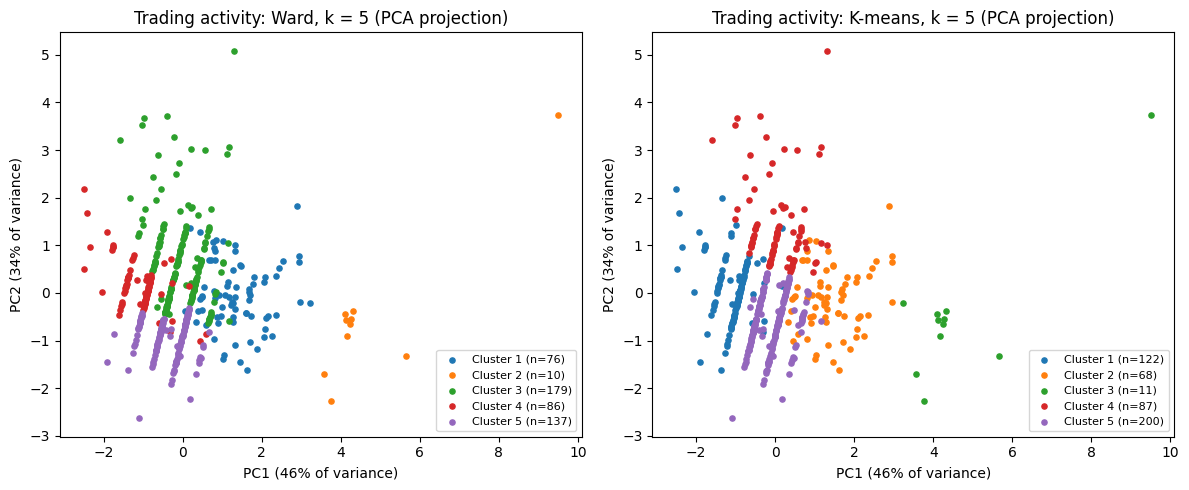


Risk/return: ARI Ward vs K-means = 0.438
K-means   1    2    3   4
Ward                     
1        29    0    0  63
2        12  128    7  37
3         0    0   37  61
4         0    4  110   0

Trading activity: ARI Ward vs K-means = 0.434
K-means   1   2   3   4    5
Ward                        
1         1  66   1   4    4
2         0   0  10   0    0
3        14   0   0  83   82
4        84   2   0   0    0
5        23   0   0   0  114


In [30]:
# Labelled 2D visuals: risk matrix is already 2D, activity matrix uses PCA
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, col, title in zip(ax, ["ward_risk", "kmeans_risk"], ["Ward", "K-means"]):
    for c in sorted(final[col].unique()):
        m = final[col] == c
        a.scatter(ft.loc[m, "weekly_beta"], ft.loc[m, "mean_weekly_return"], s=14, label=f"Cluster {c} (n={m.sum()})")
    a.set_xlabel("Weekly beta"); a.set_ylabel("Mean weekly return"); a.set_title(f"Risk/return: {title}, k = {K_RISK}"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{folder}/clusters_risk.png", dpi=200, bbox_inches="tight"); plt.show()

pca = PCA(n_components=2, random_state=SEED).fit(Z_act)
P = pca.transform(Z_act)
print("PCA explained variance:", pca.explained_variance_ratio_.round(3), "| total", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_, columns=Z_act.columns, index=["PC1", "PC2"]).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, col, title in zip(ax, ["ward_activity", "kmeans_activity"], ["Ward", "K-means"]):
    for c in sorted(final[col].unique()):
        m = (final[col] == c).values
        a.scatter(P[m, 0], P[m, 1], s=14, label=f"Cluster {c} (n={m.sum()})")
    a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
    a.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
    a.set_title(f"Trading activity: {title}, k = {K_ACT} (PCA projection)"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{folder}/clusters_activity.png", dpi=200, bbox_inches="tight"); plt.show()

# Compare the two algorithms on the same shares
for r, w, k in [("Risk/return", "ward_risk", "kmeans_risk"), ("Trading activity", "ward_activity", "kmeans_activity")]:
    print(f"\n{r}: ARI Ward vs K-means =", round(adjusted_rand_score(final[w], final[k]), 3))
    print(pd.crosstab(final[w], final[k], rownames=["Ward"], colnames=["K-means"]))

In [32]:
# Tables for comparison side by side: medians in original units, from the saved labels and feature table
ft = pd.read_csv(f"{folder}/feature_table.csv", index_col="Ticker")
final = pd.read_csv(f"{folder}/cluster_labels_final.csv", index_col="Ticker")
ft["monetary_usd_bn"] = ft["monetary_usd"] / 1e9

def profile_table(cols, label_cols, rename):
    parts = []
    for algo, lab in label_cols:
        g = ft[cols].groupby(final[lab])
        t = g.median().round(3)
        t.insert(0, "Shares", g.size())
        t.insert(0, "Cluster", t.index)
        t.insert(0, "Algorithm", algo)
        parts.append(t.reset_index(drop=True))
    return pd.concat(parts, ignore_index=True).rename(columns=rename)

# Table 2a: risk/return
table2a = profile_table(["mean_weekly_return", "weekly_beta"],
                        [("Ward", "ward_risk"), ("K-means", "kmeans_risk")],
                        {"mean_weekly_return": "Median weekly return", "weekly_beta": "Median weekly beta"})

# Table 2b: trading activity
table2b = profile_table(["recency_days", "frequency", "monetary_usd_bn"],
                        [("Ward", "ward_activity"), ("K-means", "kmeans_activity")],
                        {"recency_days": "Recency (days)", "frequency": "Frequency",
                         "monetary_usd_bn": "Monetary (USD bn)"})

print("Table 2a. Risk/return profiles (medians, original units)")
display(table2a)
print("Table 2b. Trading activity profiles (medians, original units)")
display(table2b)

table2a.to_csv(f"{folder}/table2a_risk_profiles.csv", index=False)
table2b.to_csv(f"{folder}/table2b_activity_profiles.csv", index=False)

Table 2a. Risk/return profiles (medians, original units)


,Algorithm,Cluster,Shares,Median weekly return,Median weekly beta
0,Ward,1,92,0.006,1.218
1,Ward,2,184,0.002,1.089
2,Ward,3,98,0.004,0.666
3,Ward,4,114,0.001,0.570
4,K-means,1,41,0.007,1.677
5,K-means,2,132,0.001,1.142
6,K-means,3,154,0.002,0.577
7,K-means,4,161,0.004,0.985


Table 2b. Trading activity profiles (medians, original units)


,Algorithm,Cluster,Shares,Recency (days),Frequency,Monetary (USD bn)
0,Ward,1,76,53.0,2.0,21.147
1,Ward,2,10,102.0,0.0,23.786
2,Ward,3,179,11.0,3.0,34.321
3,Ward,4,86,11.0,4.0,13.371
4,Ward,5,137,11.0,3.0,8.493
5,K-means,1,122,11.0,4.0,12.826
6,K-means,2,68,53.5,2.0,19.545
7,K-means,3,11,102.0,0.0,24.824
8,K-means,4,87,11.0,3.0,63.102
9,K-means,5,200,11.0,2.0,13.208
